# 6 · Evaluation & interpretation

| | |
|---|---|
| Lifecycle stage | 6 of 8: *Evaluation & interpretation* (metrics, explainability, business impact, uncertainty) |
| Tools | scikit-learn metrics, SHAP, ELI5, Yellowbrick |
| Code | `evaluate.py`, `explain.py`, `batch_score.py` |
| Data | the champion's scores on the **test period** (21 Jun to 31 Dec 2020), never used for any choice |

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path(os.environ.get("FRAUDLENS_ROOT") or (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())).resolve()
CODE = Path(os.environ.get("FRAUDLENS_CODE", ROOT)).resolve()
sys.path.insert(0, str(CODE / "src"))
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from fraudlens import viz
from fraudlens.utils import load_config, read_json, read_table

viz.setup()
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"   # small notebooks: plotly.js from the CDN
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
cfg = load_config(root=ROOT)
P = cfg["paths"]
print(f"Project root: {ROOT.name} | data present: {(P['silver'] / 'transactions.parquet').exists()}")
from sklearn import metrics as skm
from fraudlens import evaluate as E
from fraudlens.scoring import FraudModel
res = read_json(P["reports"] / "model_results.json")
meta = read_json(P["reports"] / "dashboard_meta.json")
fm = FraudModel.load(P["artifacts"] / "fraudlens_model.joblib")
scored = read_table(P["gold"] / "scored_transactions")
test = scored[scored["split"].astype(str) == "test"].reset_index(drop=True)
y, s, a = test["is_fraud"].to_numpy(), test["score"].to_numpy(), test["amount"].to_numpy()
thr, tcfg = meta["threshold"], cfg["model"]["threshold"]
days = (test["ts"].max() - test["ts"].min()).total_seconds() / 86400
print(f"champion {fm.champion}, threshold {thr:.4f} (chosen on validation by '{meta['threshold_strategy']}'), "
      f"{len(test):,} test transactions over {days:.0f} days")

Project root: fraudlens | data present: True


champion hist_gb, threshold 0.7397 (chosen on validation by 'min_cost'), 555,719 test transactions over 193 days


## 6.1 Headline metrics at the operating threshold

In [2]:
m = E.evaluate(y, s, a, thr, days, tcfg)
crit = cfg["success_criteria"]
checks = pd.DataFrame([
    {"metric": "recall", "value": m["recall"], "target": f">= {crit['min_test_recall']}", "met": m["recall"] >= crit["min_test_recall"]},
    {"metric": "precision", "value": m["precision"], "target": f">= {crit['min_test_precision']}", "met": m["precision"] >= crit["min_test_precision"]},
    {"metric": "alerts per day", "value": m["alerts_per_day"], "target": f"<= {crit['max_alerts_per_day']}", "met": m["alerts_per_day"] <= crit["max_alerts_per_day"]},
    {"metric": "PR-AUC lift", "value": m["pr_auc_lift"], "target": f">= {crit['min_pr_auc_lift']}", "met": m["pr_auc_lift"] >= crit["min_pr_auc_lift"]},
])
display(checks)
print(skm.classification_report(y, (s >= thr).astype(int), target_names=["legitimate", "fraud"], digits=4))
cm = pd.DataFrame(skm.confusion_matrix(y, (s >= thr).astype(int)), index=["actual legit", "actual fraud"],
                  columns=["no alert", "alert"])
cm

,metric,value,target,met
0,recall,0.9622,>= 0.9,True
1,precision,0.7240,>= 0.5,True
2,alerts per day,14.7000,<= 20,True
3,PR-AUC lift,251.2000,>= 50,True


              precision    recall  f1-score   support

  legitimate     0.9999    0.9986    0.9992    553574
       fraud     0.7240    0.9622    0.8263      2145

    accuracy                         0.9984    555719
   macro avg     0.8619    0.9804    0.9127    555719
weighted avg     0.9988    0.9984    0.9985    555719



,no alert,alert
actual legit,552787,787
actual fraud,81,2064


## 6.2 Uncertainty: bootstrap confidence intervals

The test period is one six-month sample. A percentile bootstrap (300 resamples) shows how much each
headline number could move on another sample of the same size.

In [3]:
ci = res["champion_test_ci95"]
pd.DataFrame({k: v for k, v in ci.items() if isinstance(v, dict)}).T.assign(point=lambda t: [m.get(k) for k in t.index])

,low,high,point
pr_auc,0.9632,0.9751,0.9698
precision,0.7079,0.7389,0.7240
recall,0.9527,0.9693,0.9622
f1,0.8145,0.8376,0.8263
false_positive_rate,0.0013,0.0015,0.0014
net_benefit,"909,181.9468","1,021,585.9387","964,181.8600"


## 6.3 Precision-recall trade-off and the threshold

The validation sweep (left) is what the threshold was chosen on; the test PR curve (right) shows the
same trade-off on unseen data, with the operating point marked.

In [4]:
sw = pd.DataFrame(res["validation_sweep"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(sw["alerts_per_day"], sw["recall"], label="recall", color=viz.SERIES[0])
ax.plot(sw["alerts_per_day"], sw["precision"], label="precision", color=viz.SERIES[1])
ax2 = ax.twinx(); ax2.plot(sw["alerts_per_day"], sw["net_benefit"] / 1e3, color=viz.SERIES[2], ls="--", label="net benefit ($k)")
ax.set_xscale("log"); ax.set_xlabel("alerts per day (validation)"); ax.legend(loc="center left"); ax2.legend(loc="center right")
ax.set_title("Validation sweep: more alerts buy recall at the cost of precision")
prec, rec = E.pr_curve(y, s)
axes[1].plot(rec, prec, color=viz.SERIES[0])
axes[1].scatter([m["recall"]], [m["precision"]], color=viz.SERIES[1], zorder=3, s=60, label=f"threshold {thr:.3f}")
axes[1].set(xlabel="recall", ylabel="precision", title=f"Test PR curve (PR-AUC {m['pr_auc']:.3f}, baseline {m['pr_auc_baseline']:.4f})")
axes[1].legend()
plt.tight_layout(); plt.show()

### Yellowbrick: the same curve from the fitted estimator

Yellowbrick wraps the already-fitted champion (`is_fitted=True`) and draws its precision-recall curve on
the test matrix, an independent check of the numbers above.

In [5]:
from yellowbrick.classifier import PrecisionRecallCurve
Xt = fm.transform(read_table(P["gold"] / "features_test"))
yt = read_table(P["gold"] / "features_test")["is_fraud"].to_numpy()
# Yellowbrick 1.5 predates scikit-learn's estimator tags; declare the estimator type it looks for.
fm.model._estimator_type = "classifier"
fig, ax = plt.subplots(figsize=(6, 4))
viz_pr = PrecisionRecallCurve(fm.model, is_fitted=True, classes=["legit", "fraud"], ax=ax, ap_score=True, iso_f1_curves=True)
few = np.r_[np.flatnonzero(yt == 1)[:50], np.arange(500)]
viz_pr.fit(Xt.iloc[few], yt[few])            # no refit (is_fitted=True): fit() only records the classes
viz_pr.score(Xt, yt)
viz_pr.finalize(); plt.show()
print(f"Yellowbrick average precision: {viz_pr.score_:.4f}")

Yellowbrick average precision: 0.9698


## 6.4 Calibration and stability over time

In [6]:
cal = pd.DataFrame(res["champion_calibration"])
mon = pd.DataFrame(res["champion_monthly_test"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot([0, 1], [0, 1], ls="--", color=viz.MUTED)
axes[0].plot(cal["mean_score"], cal["fraud_rate"], marker="o", color=viz.SERIES[0])
axes[0].set(xlabel="mean score in bin", ylabel="observed fraud rate", title="Calibration (score deciles, test)")
axes[1].plot(mon["period"], mon["recall"], marker="o", label="recall", color=viz.SERIES[0])
axes[1].plot(mon["period"], mon["precision"], marker="o", label="precision", color=viz.SERIES[1])
axes[1].set(ylim=(0, 1.05), title="Monthly performance on the test period"); axes[1].legend()
plt.tight_layout(); plt.show()
mon[["period", "transactions", "frauds", "alerts", "precision", "recall", "net_benefit"]]

,period,transactions,frauds,alerts,precision,recall,net_benefit
0,2020-06,30058,133,173,0.7457,0.9699,"62,809.9300"
1,2020-07,85848,321,424,0.7146,0.9439,"135,548.1800"
2,2020-08,88759,415,532,0.7556,0.9687,"176,447.3400"
3,2020-09,69533,340,442,0.7376,0.9588,"171,242.9700"
4,2020-10,69348,384,511,0.7260,0.9661,"167,446.3300"
5,2020-11,72635,294,404,0.7129,0.9796,"131,617.7400"
6,2020-12,139538,258,365,0.6712,0.9496,"119,069.3600"


The scores rank very well but are **not calibrated probabilities**: class weighting inflates them, so a
score of 0.74 does not mean a 74% fraud probability. That is acceptable for ranking and thresholding, and
the threshold is set on validation in score units; if probabilities were needed (e.g. for expected-loss
reporting) an isotonic calibration step on validation would be added.

## 6.5 Business impact

In [7]:
impact = pd.Series({
    "fraud transactions in test": int(y.sum()),
    "caught": m["true_positives"], "missed": m["false_negatives"], "false alerts": m["false_positives"],
    "fraud $ in test": round(float(a[y == 1].sum()), 2),
    "fraud $ caught (x0.9 recovered)": m["fraud_amount_caught"],
    "fraud $ missed": m["fraud_amount_missed"],
    "review cost ($15/alert)": m["review_cost"],
    "net benefit": m["net_benefit"],
    "alerts per day": m["alerts_per_day"],
    "good customers questioned per fraud caught": m["false_alarms_per_catch"],
    "break-even review cost per alert ($)": res.get("break_even_review_cost"),
})
impact.to_frame("test period").style.format(lambda v: f"{v:,.2f}" if isinstance(v, float) else f"{v:,}")

,test period
fraud transactions in test,"2,145.00"
caught,"2,064.00"
missed,81.00
false alerts,787.00
fraud $ in test,"1,133,324.68"
fraud $ caught (x0.9 recovered),"1,006,946.86"
fraud $ missed,"14,494.84"
review cost ($15/alert),"42,765.00"
net benefit,"964,181.86"
alerts per day,14.70


## 6.6 Error analysis: what the model misses, and who gets false alerts

In [8]:
test["amount_band"] = pd.cut(test["amount"], [0, 10, 50, 100, 250, 500, 1000, np.inf],
                             labels=["<$10", "$10-50", "$50-100", "$100-250", "$250-500", "$500-1k", "$1k+"])
by_band = test.groupby("amount_band", observed=True).agg(
    frauds=("is_fraud", "sum"), caught=("outcome", lambda o: (o == "caught").sum()),
    missed=("outcome", lambda o: (o == "missed").sum()), false_alerts=("outcome", lambda o: (o == "false_alert").sum()))
by_band["recall"] = (by_band["caught"] / by_band["frauds"].replace(0, np.nan)).round(3)
display(by_band)
by_cat = test.groupby("category", observed=True).agg(
    frauds=("is_fraud", "sum"), missed=("outcome", lambda o: (o == "missed").sum()),
    false_alerts=("outcome", lambda o: (o == "false_alert").sum())).sort_values("missed", ascending=False)
by_cat.head(8)

,frauds,caught,missed,false_alerts,recall
amount_band,,,,,
<$10,150,138,12,136,0.9200
$10-50,312,282,30,278,0.9040
$50-100,18,10,8,8,0.5560
$100-250,83,67,16,72,0.8070
$250-500,546,542,4,69,0.9930
$500-1k,760,752,8,169,0.9890
$1k+,276,273,3,55,0.9890


,frauds,missed,false_alerts
category,,,
personal_care,70,15,71
food_dining,54,12,52
travel,40,10,46
kids_pets,65,9,88
home,67,7,42
misc_pos,72,6,72
health_fitness,52,5,47
misc_net,267,4,100


Missed fraud is concentrated in **small amounts**: low-value test transactions on compromised cards look
like ordinary spending, and an alert on them would cost more than it saves. This is a deliberate outcome of
the cost-based threshold, not a blind spot.

## 6.7 Fairness check

The model does not use the customer's name, address or exact location, but it does use `age` and `gender`.
Recall and false-alarm rates by group show whether any group is treated noticeably worse.

In [9]:
test["age_band"] = pd.cut(test["age"], [0, 25, 35, 45, 55, 65, 120], labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"])
def group_metrics(g):
    yy, aa = g["is_fraud"].to_numpy(), g["alert"].to_numpy()
    return pd.Series({"transactions": len(g), "frauds": int(yy.sum()),
                      "recall": round(float(aa[yy == 1].mean()), 3) if yy.sum() else np.nan,
                      "false_alarm_rate_per_10k": round(1e4 * float(aa[yy == 0].mean()), 2),
                      "precision": round(float(yy[aa == 1].mean()), 3) if aa.sum() else np.nan})
fair = pd.concat({"gender": test.groupby("gender", observed=True).apply(group_metrics),
                  "age band": test.groupby("age_band", observed=True).apply(group_metrics)})
fair.reset_index(names=["group", "value"]).to_json(P["reports"] / "fairness.json", orient="records", indent=1)
fair

transactions     frauds  recall  false_alarm_rate_per_10k  precision
gender   F      304,886.0000 1,164.0000  0.9470                   15.6700     0.6980
         M      250,833.0000   981.0000  0.9810                   12.4500     0.7560
age band <25     46,931.0000   153.0000  0.9930                   15.8200     0.6730
         25-34  113,806.0000   427.0000  0.9600                   17.8200     0.6700
         35-44  120,059.0000   386.0000  0.9590                   16.3800     0.6540
         45-54  115,736.0000   427.0000  0.9440                   13.3600     0.7240
         55-64   68,556.0000   342.0000  0.9680                   12.3100     0.7980
         65+     90,631.0000   410.0000  0.9710                    8.5300     0.8380

## 6.8 Interpretation: what drives the score (SHAP)

SHAP values decompose each score (in log-odds) into feature contributions. For the HistGradientBoosting
champion with native categorical splits, TreeSHAP's values did not add up to the model output, so the
pipeline automatically switched to SHAP's model-agnostic **permutation explainer** on the same log-odds
output (exact additivity by construction).

explainer: permutation  (TreeSHAP additivity error was 14.16344)


,amount,category,amt_sum_24h,is_night,txn_count_7d,amt_sum_1h,txn_count_24h,secs_since_last_txn,hour,amt_sum_7d,log_city_pop,age
mean |SHAP|,2.8264,1.2229,1.1636,0.6626,0.5503,0.4593,0.4071,0.3865,0.3167,0.3156,0.2265,0.2048


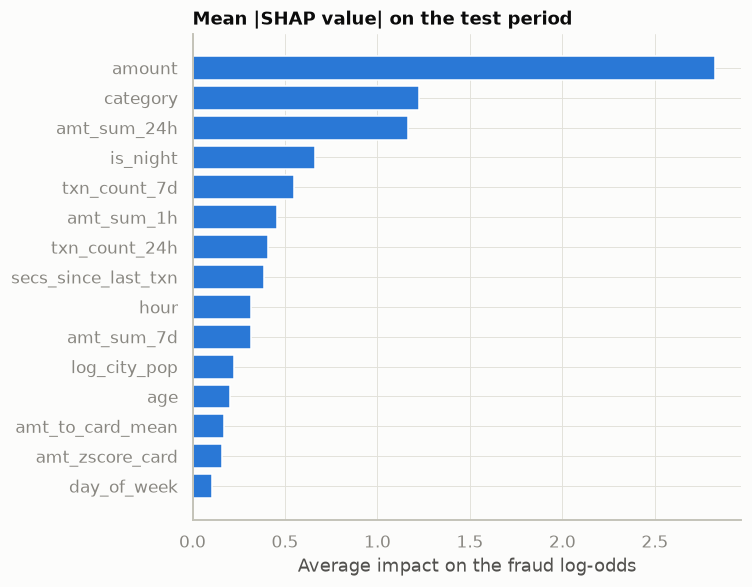

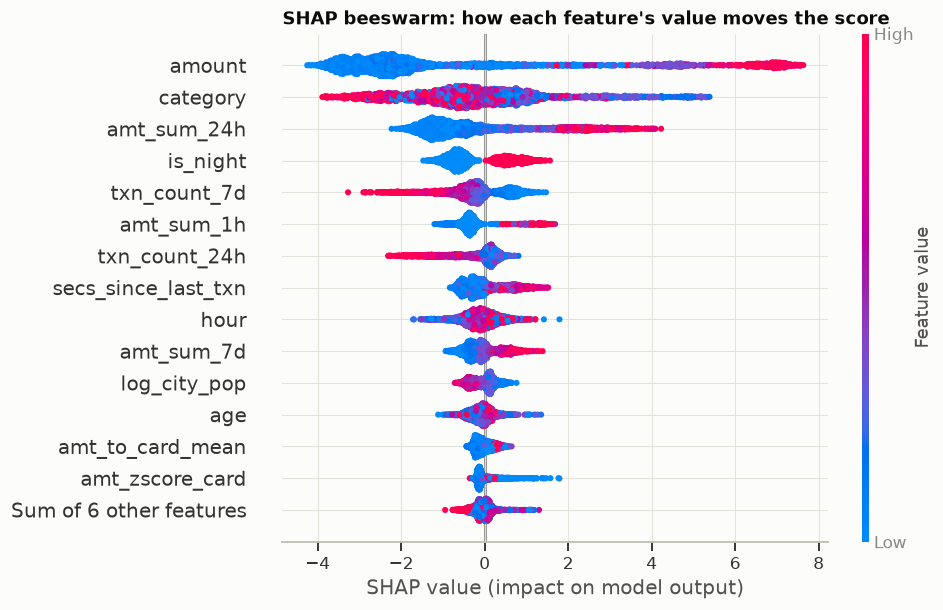

In [10]:
ex_rep = read_json(P["reports"] / "explanations.json")
print(f"explainer: {ex_rep['explainer']}  (TreeSHAP additivity error was {ex_rep['treeshap_additivity_error']})")
display(pd.Series(ex_rep["mean_abs_shap"]).head(12).to_frame("mean |SHAP|").T)
for f in ["16_shap_importance.png", "17_shap_beeswarm.png"]:
    if (P["figures"] / f).exists():
        display(Image(filename=str(P["figures"] / f), width=650))

### Local explanations, computed live

The same explainer the API uses, applied to the three highest-scoring test alerts that were real fraud and
the three highest-scoring false alerts.

In [11]:
from fraudlens.explain import Explainer
bg = read_table(P["artifacts"] / "shap_background")
ex = Explainer(fm, bg, permutations=2)
feats = read_table(P["gold"] / "features_test")
sc = fm.predict(feats)
alerts = np.flatnonzero(sc >= thr)
pick = {"caught fraud": alerts[feats["is_fraud"].to_numpy()[alerts] == 1],
        "false alert": alerts[feats["is_fraud"].to_numpy()[alerts] == 0]}
rows = []
for label, idx in pick.items():
    top3 = idx[np.argsort(-sc[idx])[:3]]
    contribs = ex.top_contributions(fm.transform(feats.iloc[top3]), k=3)
    for i, cs in zip(top3, contribs):
        rows.append({"type": label, "amount": feats["amount"].iloc[i], "category": feats["category"].iloc[i],
                     "hour": int(feats["hour"].iloc[i]), "score": round(float(sc[i]), 4),
                     **{f"reason {r + 1}": f"{c['feature']} ({c['shap']:+.2f})" for r, c in enumerate(cs)}})
pd.DataFrame(rows)

10:57:31 | INFO    | Using a permutation explainer (TreeSHAP values do not add up to the model output (max error 14.163))


,type,amount,category,hour,score,reason 1,reason 2,reason 3
0,caught fraud,908.9800,shopping_net,23,1.0000,amount (+7.20),amt_sum_24h (+2.13),txn_count_1h (+0.91)
1,caught fraud,334.5400,grocery_pos,22,1.0000,amount (+4.22),category (+2.35),amt_sum_24h (+1.94)
2,caught fraud,312.5000,grocery_pos,23,1.0000,amount (+4.36),category (+2.49),amt_sum_24h (+2.09)
3,false alert,17.7700,kids_pets,23,0.9988,amt_sum_24h (+3.54),category (+1.63),secs_since_last_txn (+1.16)
4,false alert,19.3100,health_fitness,23,0.9986,amt_sum_24h (+3.30),category (+1.76),amount (+1.75)
5,false alert,102.5300,food_dining,23,0.9982,category (+2.91),amt_sum_24h (+2.71),amt_sum_1h (+1.33)


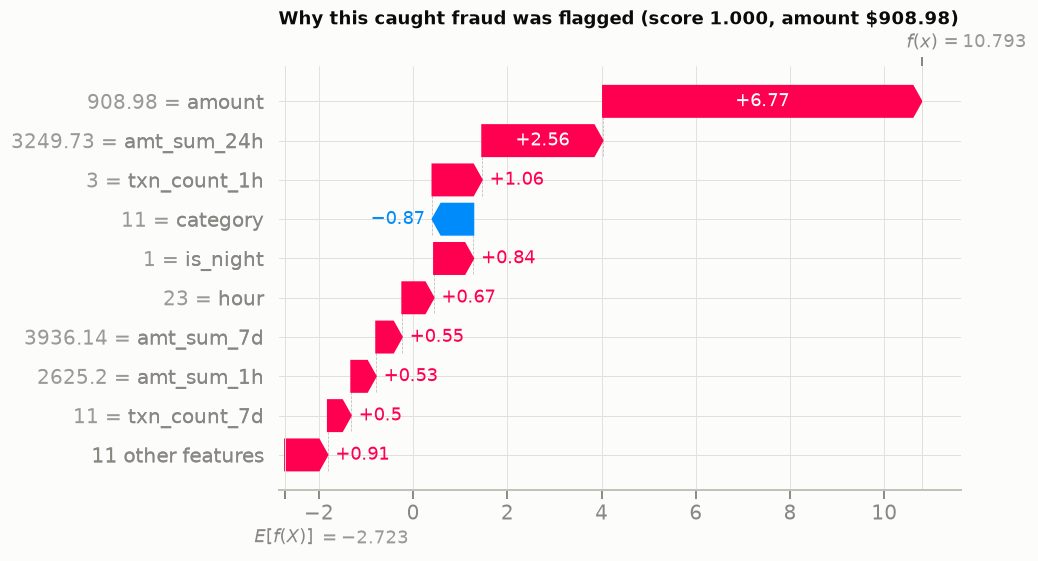

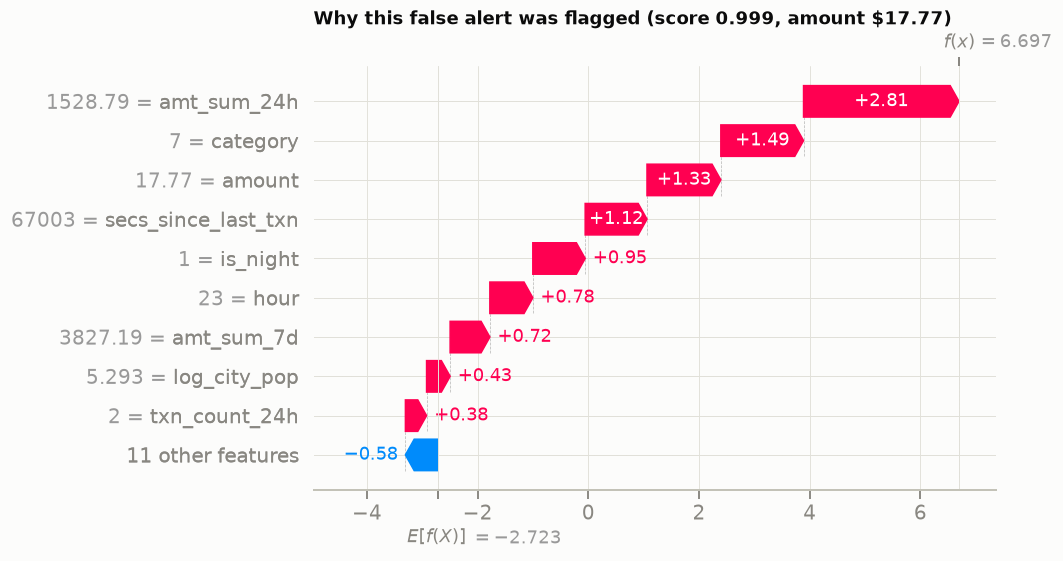

In [12]:
for f in ["18_shap_waterfall_caught_fraud.png", "18_shap_waterfall_false_alert.png"]:
    if (P["figures"] / f).exists():
        display(Image(filename=str(P["figures"] / f), width=650))

### ELI5: the transparent baseline

ELI5 shows the weights of the logistic-regression baseline. Its strongest positive weights point to the
same drivers SHAP finds in the champion (amount, recent spend, night hours, online categories), which is a
useful sanity check that the complex model learned something sensible.

In [13]:
import joblib
logit = joblib.load(P["artifacts"] / "model_logistic.joblib")
names = read_json(P["reports"] / "preprocessing_report.json")["views"]["linear"]["feature_names"]
try:
    import eli5
    from eli5.formatters.as_dataframe import format_as_dataframe
    w = format_as_dataframe(eli5.explain_weights(logit, feature_names=names, top=15))
    display(w)
except Exception as exc:   # ELI5 is unmaintained; fall back to the same table from the coefficients
    print(f"ELI5 unavailable with this scikit-learn ({type(exc).__name__}); showing the coefficients directly")
    coef = pd.Series(logit.coef_[0], index=names).sort_values(key=abs, ascending=False).head(15)
    display(coef.to_frame("weight"))

,target,feature,weight
0,1,is_night,2.6802
1,1,amt_sum_7d,2.1241
2,1,category_gas_transport,2.0222
3,1,amt_to_card_mean,2.0053
4,1,category_grocery_net,1.6770
5,1,amt_sum_24h,1.3873
6,1,category_grocery_pos,1.0649
7,1,category_entertainment,-1.2666
8,1,gender_F,-1.3454
9,1,gender_M,-1.5240


## 6.9 Summary

* On the untouched test period the champion meets every success criterion (see 6.1), with tight bootstrap
  intervals.
* About 14-15 alerts a day; roughly three in four alerts are real fraud, and ~96% of fraud is caught,
  including nearly all high-value fraud. The money that is missed is mostly in small transactions, by design.
* Large amounts relative to the card's history, a burst of spending in the last 24 hours, night-time and
  online/grocery-POS categories drive the alerts, consistent with the EDA hypotheses.
* Recall is high for every group, but not identical: it is lower for women than for men and women see slightly
  more false alarms per 10,000 transactions (table in 6.7). The gap is reported, not hidden; on real data it
  would be investigated (e.g. dropping `gender` and re-checking) before deployment, and monitoring tracks it.

**Next:** [07 · Deployment & visualisation](07_deployment_visualisation.ipynb)